# plutovizu — Climat, sols et pédologie

API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`. Le thème **editorial** est appliqué dès l'import. Fiches détaillées (données attendues, paramètres) dans la [documentation](https://mr-kam.github.io/plutovizu/).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

## Données d'exemple

Jeux de données fictifs utilisés dans ce notebook.

In [2]:
rng = np.random.default_rng(21)
t = np.arange(90)
meteo = pd.DataFrame({'jour': pd.date_range('2024-06-01', periods=90, freq='D'),
                      'tmoy': 28 - 3 * np.sin(t / 90 * np.pi) + rng.normal(0, 0.6, 90)})
meteo['tmin'] = meteo['tmoy'] - rng.uniform(4, 6, 90)
meteo['tmax'] = meteo['tmoy'] + rng.uniform(4, 7, 90)

## Diagramme ombrothermique

Échelle de Gaussen (p = 2T) : un mois est sec quand les précipitations sont inférieures au double de la température.

Analyse des périodes sèches et humides:
Jan: PÉRIODE SÈCHE - Précip: 16.0mm < Seuil: 48.2mm
Fév: PÉRIODE SÈCHE - Précip: 23.9mm < Seuil: 52.2mm
Mar: Période humide - Précip: 86.7mm ≥ Seuil: 53.2mm
Avr: Période humide - Précip: 116.7mm ≥ Seuil: 53.0mm
Mai: Période humide - Précip: 92.9mm ≥ Seuil: 52.2mm
Juin: Période humide - Précip: 147.8mm ≥ Seuil: 50.0mm
Juil: Période humide - Précip: 143.2mm ≥ Seuil: 47.8mm
Août: Période humide - Précip: 215.8mm ≥ Seuil: 47.8mm
Sep: Période humide - Précip: 167.1mm ≥ Seuil: 48.6mm
Oct: Période humide - Précip: 109.4mm ≥ Seuil: 49.6mm
Nov: PÉRIODE SÈCHE - Précip: 30.3mm < Seuil: 49.8mm
Déc: PÉRIODE SÈCHE - Précip: 33.0mm < Seuil: 47.4mm

Résumé: 4 mois secs sur 12 mois


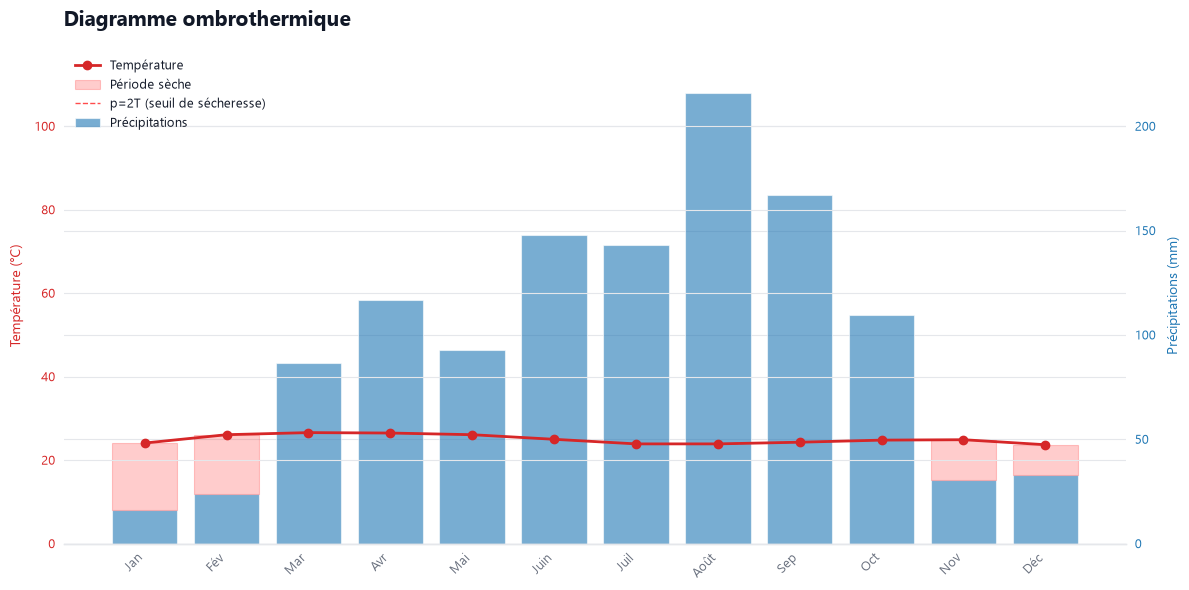

In [3]:
climat = pd.DataFrame({
    'Mois': ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin',
             'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc'],
    'Température (°C)': [24.1, 26.1, 26.6, 26.5, 26.1, 25.0,
                         23.9, 23.9, 24.3, 24.8, 24.9, 23.7],
    'Précipitations (mm)': [16, 23.9, 86.7, 116.7, 92.9, 147.8,
                            143.2, 215.8, 167.1, 109.4, 30.3, 33],
})
cols = ('Mois', 'Température (°C)', 'Précipitations (mm)')

(Chart(climat, figsize=(12, 6))
    .ombrothermic(*cols)
    .title('Diagramme ombrothermique')
    .print_ombrothermic_analysis(*cols)
    .tight_layout()
    .show())

Variante en **deux courbes** : `kind='lines'` hachure les périodes sèches entre les courbes (là où P < 2T).

Mois secs : ['Jan', 'Fév', 'Nov', 'Déc']


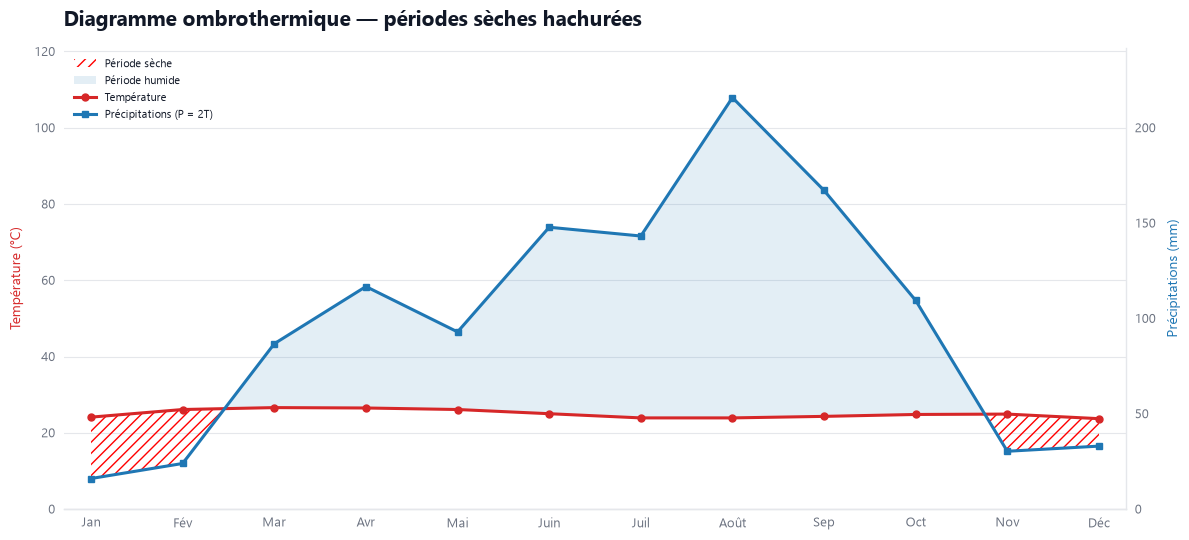

In [4]:
chart = (Chart(climat, figsize=(12, 5.5))
    .ombrothermic(*cols, kind='lines')
    .title('Diagramme ombrothermique — périodes sèches hachurées')
    .tight_layout())
print('Mois secs :', chart.dry_months)
chart.show()

## Climat & sols

Une station **fictive** de climat soudanien (valeurs illustratives).

{'t_moyenne': 27.416666666666668, 'p_totale': 1096.0, 'mois_secs': ['Jan', 'Fév', 'Mar', 'Avr', 'Nov', 'Déc']}


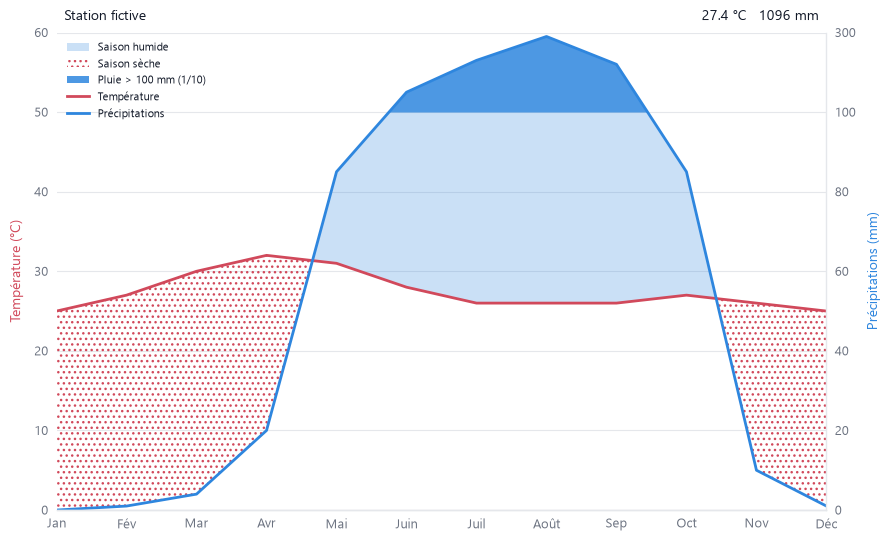

{'excedent': 380.0, 'deficit': 1134.0}


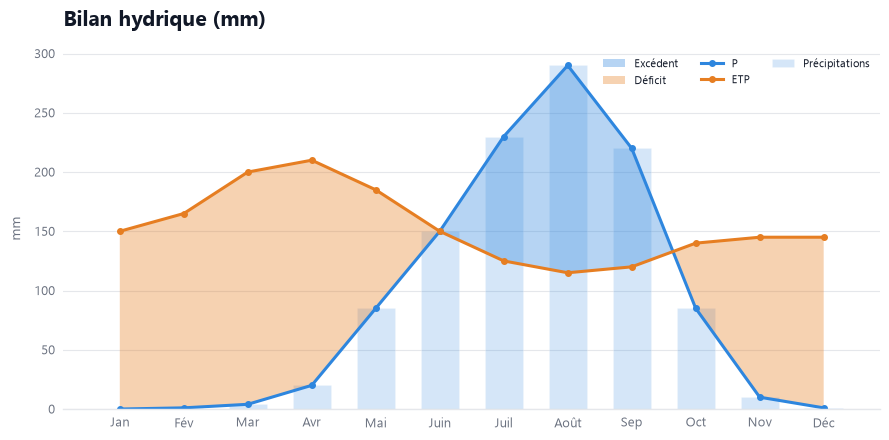

In [5]:
station = pd.DataFrame({
    'mois': ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc'],
    'temperature': [25, 27, 30, 32, 31, 28, 26, 26, 26, 27, 26, 25],
    'pluie': [0, 1, 4, 20, 85, 150, 230, 290, 220, 85, 10, 1],
    'tmin': [17, 19, 22, 25, 24, 22, 21, 21, 21, 21, 19, 17],
    'etp': [150, 165, 200, 210, 185, 150, 125, 115, 120, 140, 145, 145],
})

chart = (Chart(station, figsize=(9, 5.5))
    .walter_lieth('mois', 'temperature', 'pluie', tmin='tmin', station='Station fictive')
    .tight_layout())
print(chart.climate_summary)
chart.show()

chart = (Chart(station, figsize=(9, 4.5))
    .water_balance('mois', 'pluie', 'etp')
    .title('Bilan hydrique (mm)')
    .tight_layout())
print(chart.water_summary)
chart.show()

{'Tallage': Timestamp('2024-07-07 00:00:00'), 'Floraison': Timestamp('2024-08-17 00:00:00')}


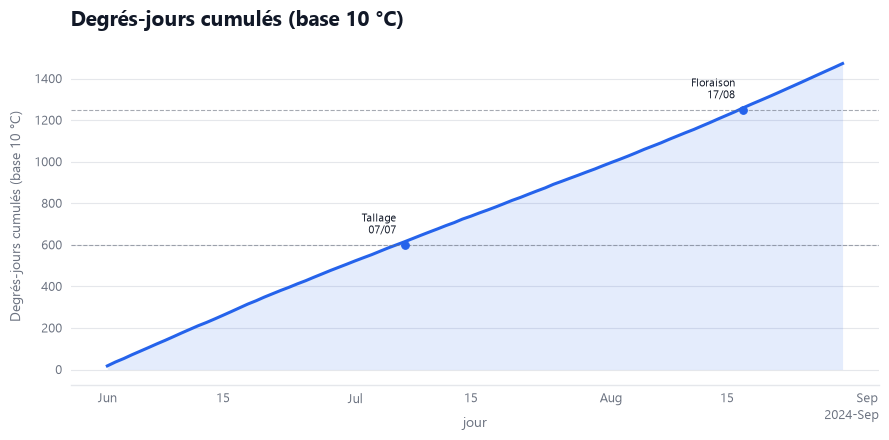

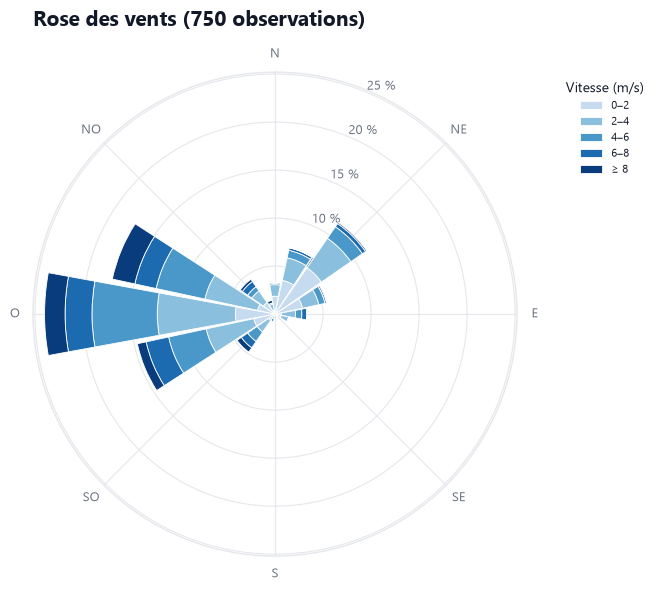

In [6]:
chart = (Chart(meteo, figsize=(9, 4.5))
    .degree_days('jour', 'tmin', 'tmax', base=10, cap=35,
                 stages={'Tallage': 600, 'Floraison': 1250})
    .title('Degrés-jours cumulés (base 10 °C)')
    .tight_layout())
print(chart.stage_dates)
chart.show()

rng = np.random.default_rng(12)
vent_obs = pd.DataFrame({
    'direction': np.concatenate([rng.normal(270, 25, 500), rng.normal(45, 30, 250)]) % 360,
    'vitesse': np.concatenate([rng.gamma(3, 1.4, 500), rng.gamma(2, 1.2, 250)]),
})
(Chart(vent_obs, figsize=(7, 6))
    .wind_rose('direction', 'vitesse')
    .title('Rose des vents (750 observations)')
    .tight_layout()
    .show())

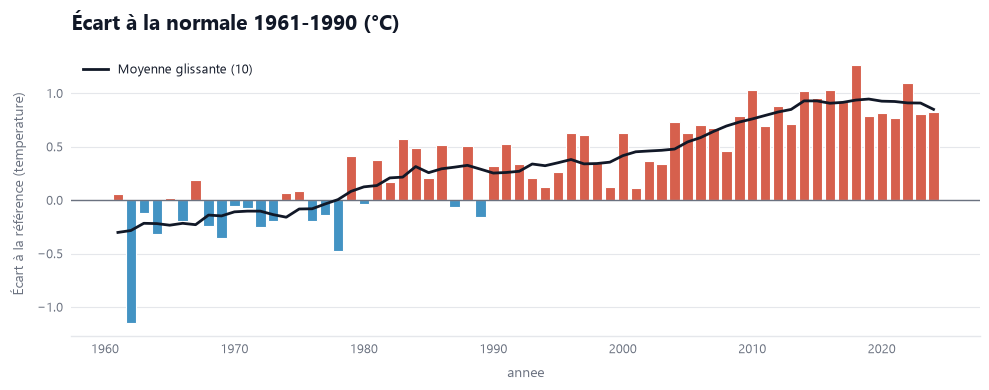

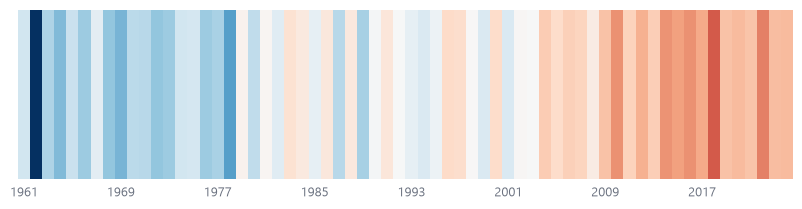

In [7]:
rng = np.random.default_rng(13)
annees = pd.DataFrame({'annee': np.arange(1961, 2025)})
annees['temperature'] = 26.8 + 0.022 * (annees['annee'] - 1961) + rng.normal(0, 0.25, len(annees))

(Chart(annees, figsize=(10, 4))
    .anomaly('annee', 'temperature', baseline=(1961, 1990), window=10)
    .title('Écart à la normale 1961-1990 (°C)')
    .tight_layout()
    .show())

Chart(annees, figsize=(10, 2.2)).climate_stripes('annee', 'temperature').show()

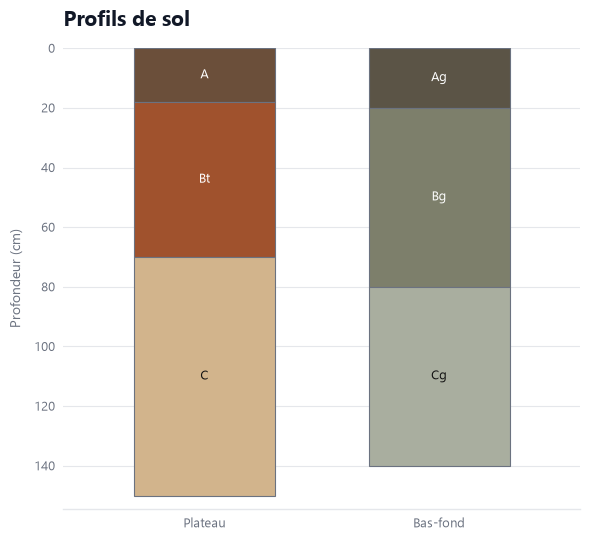

In [8]:
horizons = pd.DataFrame({
    'fosse': ['Plateau'] * 3 + ['Bas-fond'] * 3,
    'horizon': ['A', 'Bt', 'C', 'Ag', 'Bg', 'Cg'],
    'haut': [0, 18, 70, 0, 20, 80],
    'bas': [18, 70, 150, 20, 80, 140],
    'couleur': ['#6b4f3a', '#a0522d', '#d2b48c', '#5b5446', '#7d7f6b', '#a9ae9f'],
})
(Chart(horizons, figsize=(6, 5.5))
    .soil_profile('haut', 'bas', 'horizon', profile='fosse', color='couleur')
    .title('Profils de sol')
    .tight_layout()
    .show())

### Pédologie

Propriétés par horizon, courbe pF, granulométrie, complexe d'échange, infiltration et isoplèthes (données **fictives**).

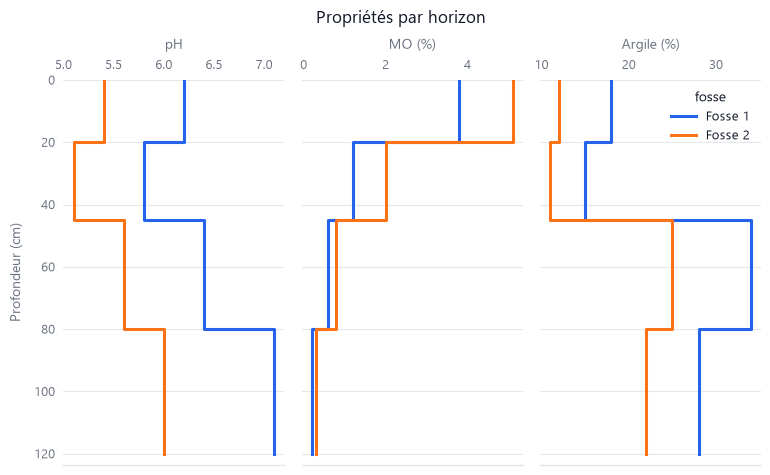

In [9]:
proprietes = pd.DataFrame({
    'fosse': ['Fosse 1'] * 4 + ['Fosse 2'] * 4,
    'haut': [0, 20, 45, 80] * 2, 'bas': [20, 45, 80, 120] * 2,
    'pH': [6.2, 5.8, 6.4, 7.1, 5.4, 5.1, 5.6, 6.0],
    'MO (%)': [3.8, 1.2, 0.6, 0.2, 5.1, 2.0, 0.8, 0.3],
    'Argile (%)': [18, 15, 34, 28, 12, 11, 25, 22]})
(Chart(proprietes, figsize=(9, 5))
    .soil_properties('haut', ['pH', 'MO (%)', 'Argile (%)'], bottom='bas', group='fosse')
    .title('Propriétés par horizon')
    .show())

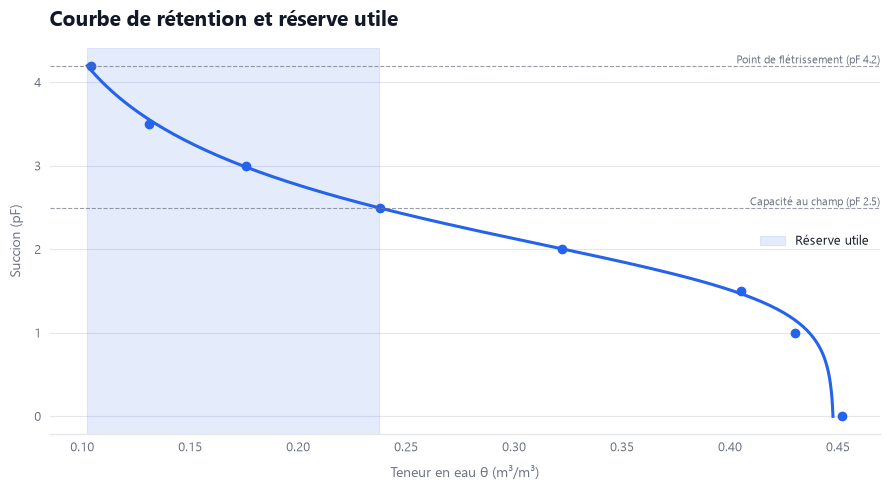

,theta_r,theta_s,alpha,n,capacite_champ,point_fletrissement,reserve_utile
0,0.069,0.448,0.021,1.42,0.237,0.102,0.135


In [10]:
retention = pd.DataFrame({
    'pF': [0, 1, 1.5, 2, 2.5, 3, 3.5, 4.2],
    'theta': [0.452, 0.430, 0.405, 0.322, 0.238, 0.176, 0.131, 0.104]})
chart = (Chart(retention, figsize=(9, 5))
    .retention_curve('pF', 'theta')
    .labels('Teneur en eau θ (m³/m³)')
    .title('Courbe de rétention et réserve utile')
    .tight_layout())
chart.show()
chart.retention.round(3)

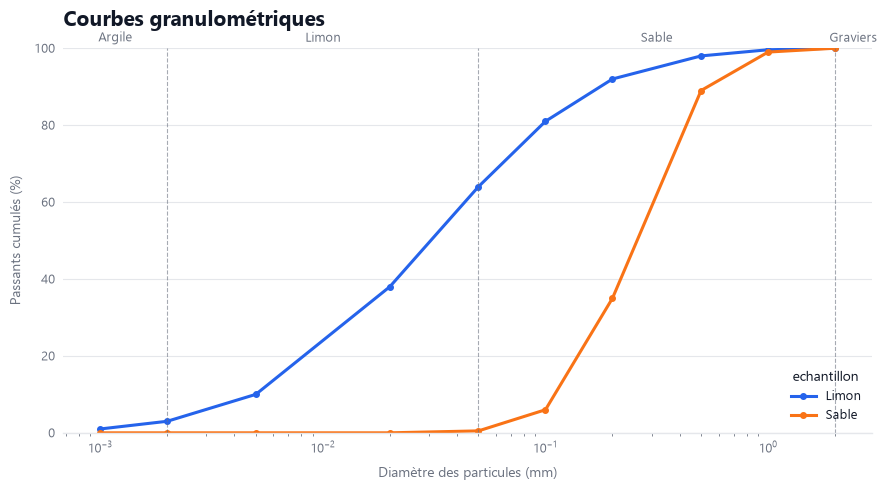

,groupe,D10,D30,D60,Cu,Cc
0,Limon,0.005,0.0135,0.0434,8.6852,0.8343
1,Sable,0.110,0.1775,0.3057,2.7781,0.9364


In [11]:
diam = np.array([0.001, 0.002, 0.005, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2])
granulo = pd.DataFrame({'diametre_mm': np.tile(diam, 2),
                        'passant': [1, 3, 10, 38, 64, 81, 92, 98, 99.6, 100,
                                    0, 0, 0, 0, .5, 6, 35, 89, 99, 100],
                        'echantillon': ['Limon'] * 10 + ['Sable'] * 10})
chart = Chart(granulo, figsize=(9, 5)).grain_size_curve('diametre_mm', 'passant', group='echantillon')
chart.title('Courbes granulométriques').tight_layout().show()
chart.grain_size.round(4)

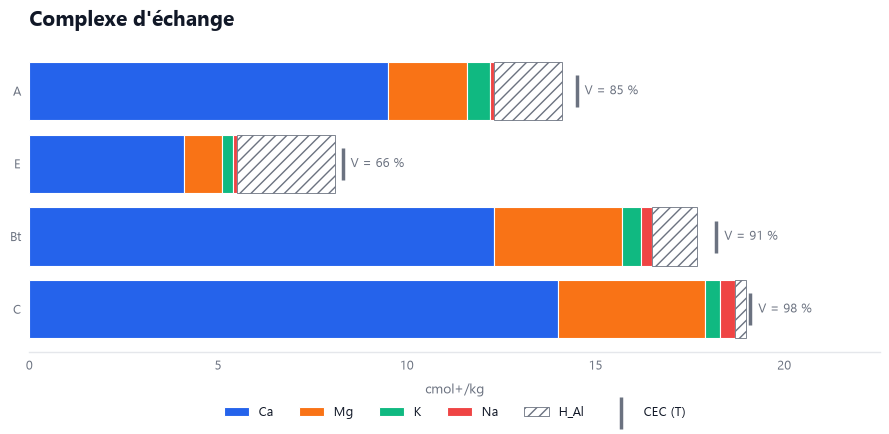

A     84.8
E     66.3
Bt    90.7
C     97.9
Name: V (%), dtype: float64

In [12]:
complexe = pd.DataFrame({'horizon': ['A', 'E', 'Bt', 'C'],
                         'Ca': [9.5, 4.1, 12.3, 14.0], 'Mg': [2.1, 1.0, 3.4, 3.9],
                         'K': [0.6, 0.3, 0.5, 0.4], 'Na': [0.1, 0.1, 0.3, 0.4],
                         'H_Al': [1.8, 2.6, 1.2, 0.3], 'CEC': [14.5, 8.3, 18.2, 19.1]})
chart = Chart(complexe, figsize=(9, 4.5)).exchange_complex('horizon', ['Ca', 'Mg', 'K', 'Na'], acidity='H_Al', cec='CEC')
chart.title('Complexe d\'échange').tight_layout().show()
chart.base_saturation.round(1)

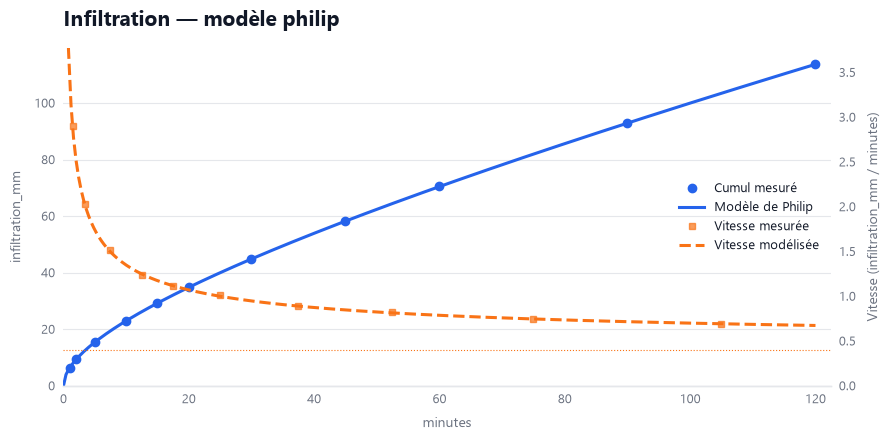

{'model': 'philip', 'S': 5.999, 'A': 0.4, 'final_rate': 0.4}


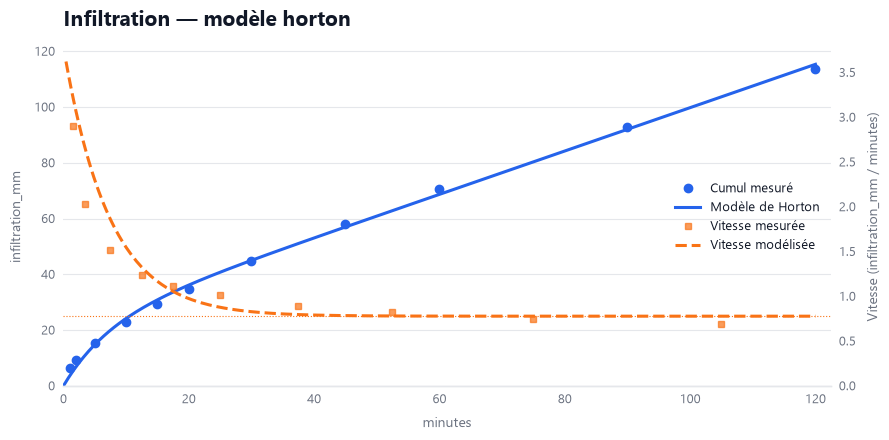

{'model': 'horton', 'f0': 3.782, 'fc': 0.777, 'k': 0.136, 'final_rate': 0.777}


In [13]:
t = np.array([1, 2, 5, 10, 15, 20, 30, 45, 60, 90, 120])
essai_infiltration = pd.DataFrame({'minutes': t, 'infiltration_mm': (6 * np.sqrt(t) + .4 * t).round(1)})
for modele in ('philip', 'horton'):
    chart = (Chart(essai_infiltration, figsize=(9, 4.5))
        .infiltration_curve('minutes', 'infiltration_mm', model=modele)
        .title(f'Infiltration — modèle {modele}')
        .tight_layout())
    chart.show()
    print({k: round(v, 3) if isinstance(v, float) else v for k, v in chart.infiltration.items()})

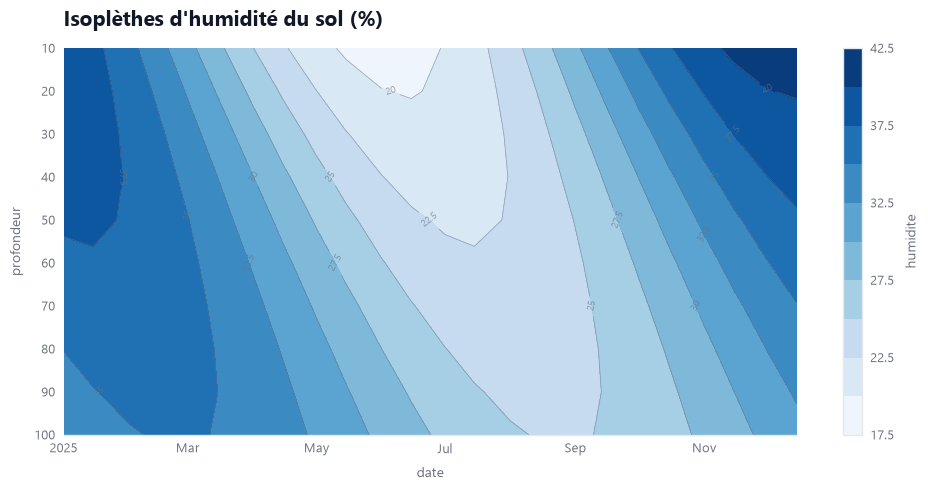

In [14]:
dates = pd.date_range('2025-01-01', periods=24, freq='SMS')
humidite_sol = pd.DataFrame(
    [(dt, z, 30 - 12 * np.sin(2 * np.pi * (dt.dayofyear / 365 - .15 - z / 400)) * np.exp(-z / 120))
     for dt in dates for z in range(10, 110, 10)],
    columns=['date', 'profondeur', 'humidite'])
(Chart(humidite_sol, figsize=(10, 5))
    .isopleth('date', 'profondeur', 'humidite', cmap='Blues')
    .title('Isoplèthes d\'humidité du sol (%)')
    .tight_layout()
    .show())